In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [34]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

In [35]:
SEASONS = [
    "2021-22",
    "2022-23",
    "2023-24",
    "2024-25",
    "2025-26",
]

In [36]:
players = pd.read_csv("basketball_data/player_stats_five_seasons.csv")
players.head()

,PLAYER_ID,PLAYER_NAME,NICKNAME,TEAM_ID,TEAM_ABBREVIATION,AGE,GP,W,L,W_PCT,...,TS_PCT_RANK,USG_PCT_RANK,E_USG_PCT_RANK,E_PACE_RANK,PACE_RANK,sp_work_PACE_RANK,PIE_RANK,FGM_PG_RANK,FGA_PG_RANK,SEASON
0,203932,Aaron Gordon,Aaron,1610612743,DEN,26.0,75,46,29,0.613,...,124,200,211,354,463,463,218,81,106,2021-22
1,1630565,Aaron Henry,Aaron,1610612755,PHI,22.0,6,6,0,1.000,...,576,402,355,26,47,47,596,573,581,2021-22
2,1628988,Aaron Holiday,Aaron,1610612756,PHX,25.0,63,34,29,0.540,...,328,248,246,428,400,400,272,320,310,2021-22
3,1630174,Aaron Nesmith,Aaron,1610612738,BOS,22.0,52,32,20,0.615,...,435,324,316,318,312,312,510,440,434,2021-22
4,1630598,Aaron Wiggins,Aaron,1610612760,OKC,23.0,50,13,37,0.260,...,279,399,397,239,208,208,461,236,240,2021-22


In [37]:
players["THREE_POINT_ATTEMPT_RATE"] = (
    players["FG3A"] / players["FGA"].replace(0, np.nan)
)

players["AST_TO_TOV"] = (
    players["AST"] / players["TOV"].replace(0, np.nan)
)

features = [
    "USG_PCT",
    "TS_PCT",
    "AST_PCT",
    "TOV",
    "AST_TO_TOV",
    "THREE_POINT_ATTEMPT_RATE",
    "FT_PCT",
    "OREB",
    "PIE",
    "DREB",
    "STL",
    "BLK"
]

available_features = [
    col for col in features
    if col in players.columns
]

print("Available features:", available_features)

Available features: ['USG_PCT', 'TS_PCT', 'AST_PCT', 'TOV', 'AST_TO_TOV', 'THREE_POINT_ATTEMPT_RATE', 'FT_PCT', 'OREB', 'PIE', 'DREB', 'STL', 'BLK']


C:\Users\ashli\AppData\Local\Temp\ipykernel_13872\1207200067.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  players["THREE_POINT_ATTEMPT_RATE"] = (
C:\Users\ashli\AppData\Local\Temp\ipykernel_13872\1207200067.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  players["AST_TO_TOV"] = (


In [38]:
eligible = players[
    (players["GP"] >= 20) &
    (players["MIN"] >= 10)
].copy()

print("Total player-season rows:", len(players))
print("Eligible player-season rows:", len(eligible))

Total player-season rows: 2867
Eligible player-season rows: 2025


In [39]:
feature_data = eligible[available_features].copy()

feature_data = feature_data.replace(
    [np.inf, -np.inf],
    np.nan,
)

valid_mask = feature_data.notna().all(axis=1)

eligible = eligible.loc[valid_mask].copy()
feature_data = feature_data.loc[valid_mask].copy()

print("Rows available for clustering:", len(feature_data))
feature_data.head()

Rows available for clustering: 2025


,USG_PCT,TS_PCT,AST_PCT,TOV,AST_TO_TOV,THREE_POINT_ATTEMPT_RATE,FT_PCT,OREB,PIE,DREB,STL,BLK
0,0.194,0.602,0.109,1.8,1.388889,0.315315,0.743,1.7,0.096,4.2,0.6,0.6
2,0.182,0.544,0.223,1.1,2.181818,0.296296,0.868,0.4,0.088,1.6,0.7,0.1
3,0.164,0.507,0.057,0.6,0.666667,0.628571,0.808,0.3,0.048,1.4,0.4,0.1
4,0.149,0.556,0.083,1.1,1.272727,0.417910,0.729,1.0,0.062,2.5,0.6,0.2
7,0.143,0.538,0.084,0.6,1.166667,0.617647,0.800,0.4,0.055,1.9,0.1,0.1


In [40]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(feature_data)

print("Feature matrix shape:", X_scaled.shape)

Feature matrix shape: (2025, 12)


In [41]:
results = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20,
    )

    labels = model.fit_predict(X_scaled)

    results.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": silhouette_score(X_scaled, labels),
    })

cluster_evaluation = pd.DataFrame(results)

display(cluster_evaluation)

,k,inertia,silhouette
0,2,18648.389338,0.244693
1,3,15307.026277,0.253112
2,4,14002.384889,0.174582
3,5,13055.045514,0.161827
4,6,12213.747777,0.153713
5,7,11565.744300,0.141411
6,8,11027.790184,0.139904
7,9,10616.001215,0.139577
8,10,10259.716468,0.139249


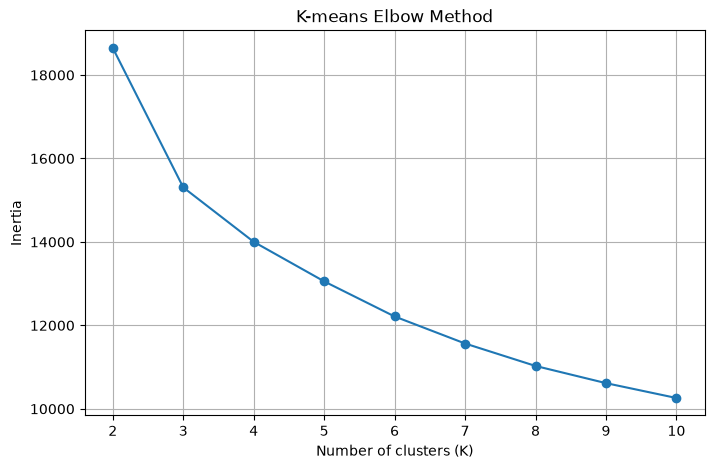

In [42]:
plt.figure(figsize=(8, 5))

plt.plot(
    cluster_evaluation["k"],
    cluster_evaluation["inertia"],
    marker="o",
)

plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("K-means Elbow Method")
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

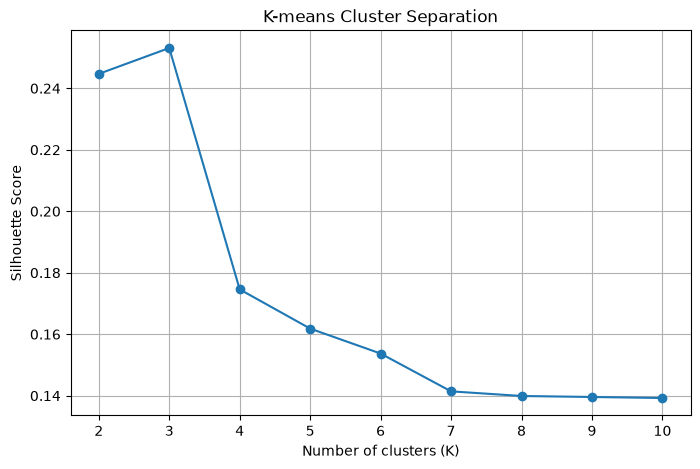

In [43]:
plt.figure(figsize=(8, 5))

plt.plot(
    cluster_evaluation["k"],
    cluster_evaluation["silhouette"],
    marker="o",
)

plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("K-means Cluster Separation")
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

In [44]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=20,
)

eligible["CLUSTER"] = kmeans.fit_predict(X_scaled)

cluster_profiles = eligible.groupby("CLUSTER")[available_features].mean()

display(cluster_profiles.round(3))

,USG_PCT,TS_PCT,AST_PCT,TOV,AST_TO_TOV,THREE_POINT_ATTEMPT_RATE,FT_PCT,OREB,PIE,DREB,STL,BLK
CLUSTER,,,,,,,,,,,,
0,0.169,0.620,0.097,1.179,1.335,0.158,0.688,2.144,0.113,4.551,0.640,0.981
1,0.162,0.555,0.124,0.881,2.067,0.507,0.772,0.698,0.077,2.269,0.655,0.303
2,0.250,0.576,0.249,2.388,2.220,0.365,0.814,0.977,0.125,4.292,1.082,0.464


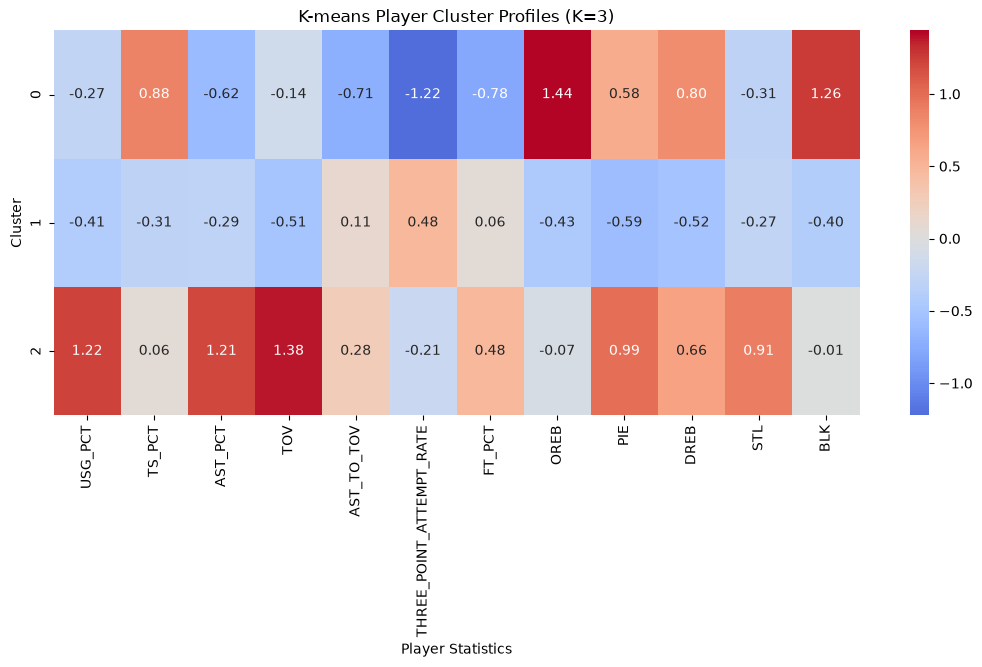

In [45]:
cluster_profiles_scaled = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=available_features,
)

plt.figure(figsize=(13, 5))

sns.heatmap(
    cluster_profiles_scaled,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
)

plt.title("K-means Player Cluster Profiles (K=3)")
plt.xlabel("Player Statistics")
plt.ylabel("Cluster")
plt.show()

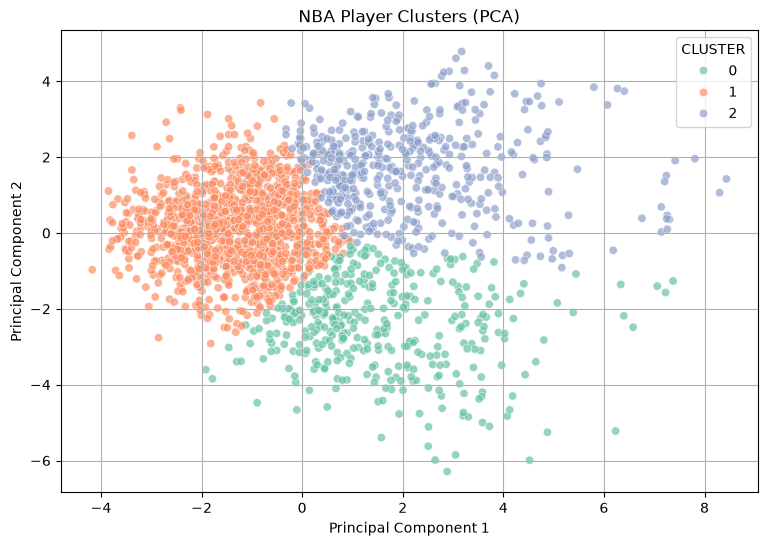

Variance explained by two components: 0.599


In [46]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

eligible["PC1"] = X_pca[:, 0]
eligible["PC2"] = X_pca[:, 1]

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=eligible,
    x="PC1",
    y="PC2",
    hue="CLUSTER",
    palette="Set2",
    alpha=0.7,
)

plt.title("NBA Player Clusters (PCA)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True)
plt.show()

print(
    "Variance explained by two components:",
    round(pca.explained_variance_ratio_.sum(), 3),
)

In [47]:
print("Cluster sizes:")
display(eligible["CLUSTER"].value_counts().sort_index())

Cluster sizes:


CLUSTER
0     376
1    1173
2     476
Name: count, dtype: int64

In [48]:
eligible.to_csv(
    "basketball_data/player_clusters_five_seasons.csv",
    index=False,
)

cluster_evaluation.to_csv(
    "basketball_data/cluster_evaluation_five_seasons.csv",
    index=False,
)

cluster_profiles.to_csv(
    "basketball_data/cluster_profiles_five_seasons.csv",
)

print("Saved clustering results.")

Saved clustering results.
